In [2]:
from google.colab import drive
drive.mount('/content/drive');

In [ ]:
!unzip "/content/drive/MyDrive/Faster-RCNN_train_test (1).zip"

###**Detectron2'yi Colab'a Yükleme**


In [6]:
!pip install pyyaml==5.1
!pip install torch==1.8.0+cu101 torchvision==0.9.0+cu101 -f https://download.pytorch.org/whl/torch_stable.html
#install old version of pytorch since detectron2 hasn't released packages for pytorch 1.9

In [7]:
!pip install detectron2 -f https://dl.fbaipublicfiles.com/detectron2/wheels/cu101/torch1.8/index.html
# After this step it will ask you to restart the runtime, please do it.

In [8]:
import torch
assert torch.__version__.startswith("1.8") 
import torchvision
import cv2

In [9]:
import os
import numpy as np
import json
import random
import matplotlib.pyplot as plt
%matplotlib inline

from detectron2.structures import BoxMode
from detectron2.data import DatasetCatalog, MetadataCatalog

### Burada, veri seti kendi özel formatındadır, bu nedenle onu ayrıştırmak ve onu dedektör2'nin standart formatına hazırlamak için bir fonksiyon yazıyoruz. Kullanıcı, özel biçimde bir veri kümesi kullanırken böyle bir işlevi kullanmalıdır.

###**Verileri Detectron2 Yapılandırmasına Uygun Şekilde Kaydetme**

Özel formata göre ayarlanacak

In [10]:
def get_data_dicts(directory, classes):
    dataset_dicts = []
    for filename in [file for file in os.listdir(directory) if file.endswith('.json')]:              #  for filename in [file for file in os.listdir(directory) if file.endswith('.json')]:
        json_file = os.path.join(directory, filename)
        with open(json_file) as f:
            img_anns = json.load(f)

        record = {}
        
        filename = os.path.join(directory, img_anns["image_path"]) #imagePath faster RCNN\images\
        record["file_name"] = filename
        record["height"] = 512
        record["width"] = 512
        annos = img_anns["shapes"] #shapes
        objs = []
        for anno in annos:
            px = [a[0] for a in anno['coords']] # x coord
            py = [a[1] for a in anno['coords']] # y-coord
#            poly = [(x, y) for x, y in zip(px, py)] # poly for segmentation
#            poly = [p for x in poly for p in x]

            obj = {
                "bbox": [np.min(px), np.min(py), np.max(px), np.max(py)],
                "bbox_mode": BoxMode.XYXY_ABS,
                "category_id": classes.index(anno['label']),
                "iscrowd": 0
            }
            objs.append(obj)
        record["annotations"] = objs
        dataset_dicts.append(record)
        
    return dataset_dicts

Burada classlar eklenecek


In [11]:
classes = ["apandiks-iltihabi" , "safra-kesesi-iltihabi","pankreas-iltihabi","bobrek-ureter-tasi", "bagirsak-divertikul-iltihabi","aort-anevrizma"] 

data_path = "/content/Faster-RCNN/"

for d in ["train", "test"]:
    DatasetCatalog.register(
        "my_" + d, 
        lambda d=d: get_data_dicts(data_path+d, classes)
    )
    MetadataCatalog.get("my_" + d).set(thing_classes=classes)

microcontroller_metadata = MetadataCatalog.get("my_train")

###**Detectron2 Object Detection Modelinin Eğitimi**


In [12]:
from detectron2 import model_zoo
from detectron2.engine import DefaultTrainer, DefaultPredictor
from detectron2.config import get_cfg
from detectron2.utils.visualizer import ColorMode, Visualizer
from matplotlib.patches import Rectangle

###**Yapılandırma Dosyasını Oluşturma**

Class sayısı ayarlanacak


In [13]:
cfg = get_cfg() # Yapılandırma Dosyasını Oluşturuyoruz
cfg.merge_from_file(model_zoo.get_config_file("COCO-Detection/faster_rcnn_R_101_FPN_3x.yaml")) # Yapılandırma Dosyasını Çeker ve Yapılandırma Dosyasına Ekler
cfg.DATASETS.TRAIN = ("my_train",) # Train Verilerimiz Yapılandırma Dosyasına Kaydeder
cfg.DATASETS.TEST = ()
cfg.DATALOADER.NUM_WORKERS = 2 # Çalışan Sayısı
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-Detection/faster_rcnn_R_101_FPN_3x.yaml") # Ağırlıkları Çeker ve Yapılandırma Dosyasına Ekler
cfg.SOLVER.IMS_PER_BATCH = 8 # Batch Size
cfg.SOLVER.BASE_LR = 0.001 # Learning Rate (Öğrenme Oranı)
cfg.SOLVER.GAMMA = 0.05 # Learning Rate Azaltma Çarpımı
cfg.SOLVER.STEPS = [500] # Learning Rate Azaltma Adım Sayısı
cfg.TEST.EVAL_PERIOD = 200 # Eğitim Sırasında Modeli Değerlendirmek İçin Adım Sayısı

cfg.SOLVER.MAX_ITER = 10000 # İterasyon Sayısı
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 6 # Sınıf Sayısı

In [14]:
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True) # Model Sonucu İçin Klasör Oluşturur
trainer = DefaultTrainer(cfg) # Modeli Train Moduna Geçirir Yapılandırma Dosyası ile Birlikte
trainer.resume_or_load(resume=False) # Model Eğitimine 0'dan Başlamak İçin False Yapıyoruz 

model_final_f6e8b1.pkl: 243MB [00:18, 13.5MB/s]                           
Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (7, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (7,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (24, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (24,) in the model! You might want to double check if this is expected.
Some model parameters or buffers are not found in the checkpoint:
roi_heads.box_p

In [ ]:
#trainer.train() # Model Eğitimine Başlar

In [ ]:
%load_ext tensorboard 
%tensorboard --logdir output

###**Eğitilmiş Model testi**

In [30]:
#cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth") # Ağırlık Dosyamızı Yapılandırma Dosyamıza Kaydeder
cfg.MODEL.WEIGHTS = "/content/drive/MyDrive/Faster Rcnn 10k_27Haziran/model_0009999.pth"    #kayıtlı modeli çalıştırma
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.6 # Test için Eşik Değerimiz
cfg.DATASETS.TEST = ("my_test", ) # Tets Verilerimiz Yapılandırma Dosyasına Kaydeder
predictor = DefaultPredictor(cfg) #Modeli Test Moduna Geçirir Yapılandırma Dosyası ile Birlikte
test_metadata = MetadataCatalog.get("my_test")
test_dataset_dicts = get_data_dicts(data_path+'test', classes)

In [31]:
os.mkdir("predict annot2")

In [ ]:
from matplotlib.pyplot import figure
from tqdm import tqdm
namelist = {}
for d in  tqdm(test_dataset_dicts):     #random.sample(test_dataset_dicts,1)
      
    img = cv2.imread(d["file_name"])
    
    outputs = predictor(img)
    v = Visualizer(img[:, :, ::-1],
                   metadata=microcontroller_metadata, 
                   scale=0.8, 
                  # instance_mode=ColorMode.IMAGE_BW # removes the colors of unsegmented pixels
    )
    v = v.draw_instance_predictions(outputs["instances"].to("cpu"))

    #plt.figure(figsize = (10, 10))
    #plt.axis("off")
    #plt.imshow(cv2.cvtColor(v.get_image()[:, :, ::-1], cv2.COLOR_BGR2RGB))
    #plt.title(d["file_name"].split("/")[4])       #file name ayırma
    #plt.show()
     

#               tahmin değerlerini txt dosyasına  yazdırma
    b = str(outputs["instances"]) 
    predictannot = b.split("tensor(")[1].strip(" device='cuda:0'), scores:")
    
    filename = str(d["file_name"].split("/")[4].strip(".jpeg"))
    #print(filename)
   
    dosya = open("/content/predict annot2/"+filename +".json", "w")
    if(predictannot == "[], device='cuda:0', size=(0, 4"):
      predictannot = "[[0,0,0,0]]"
      dosya.write(predictannot)
      dosya.close()
    else:
      dosya.write(predictannot)
      dosya.close()
    #print(b,"\n")# dosya formatını görmek isterseniz açın
    #print(predictannot)
   

  0%|          | 9/3179 [00:01<07:18,  7.23it/s]

In [29]:
import pandas as pd
import numpy as np
from glob import glob
import json
from tqdm import tqdm
iou_list = []
coordinatlist = []
ioulist = []
isimlist = []
json_list = glob("/content/Faster-RCNN/test/*.json")
jpeg_list = glob("/content/Faster-RCNN/test/*.jpeg")

for i in jpeg_list:
   img = cv2.imread(i)
   img = cv2.resize(img,(512,512))
   id_jpeg = i.split("/")[4].split(".jpeg")[0]
   title2 = id_jpeg
   for a in json_list:
     temp_id_json = a.split("/")[4].split(".json")[0]
     
     if id_jpeg == temp_id_json:
       id_json = temp_id_json
   
   
   json_file = "/content/Faster-RCNN/test/" + id_json +".json"
   
   with open(json_file) as f:
     img_anns = json.load(f)
     
   try:
    dfpredict = pd.read_json("/content/predict annot2/" + id_json + ".json")
   except ValueError as e:
     print(e)   


   annos = img_anns["shapes"] #shapes
   
   
   for anno in annos:
     title = anno["label"]
     #print(anno["label"]) 
     #print(anno["points"])
     dfanno = pd.DataFrame(anno['coords']) #mavi orjinal
     
     coordinatlist.append(anno['coords'])
     x1 = int(dfanno[0][0])
     y1 = int(dfanno[1][0])
     x2 = int(dfanno[0][1])
     y2 = int(dfanno[1][1])
     cv2.rectangle(img,(x1,y1),(x2,y2),(0,35,245), 2)
     
     try:
       for row in dfpredict.iterrows():
             #predict kırmızı 
             
         xp1 = int(row[1][0])
         yp1 = int(row[1][1])
         xp2 = int(row[1][2])
         yp2 = int(row[1][3])
     
         xA = max(x1, xp1)
         yA = max(y1, yp1)
         xB = min(x2, xp2)
         yB = min(y2, yp2)
     
         interArea = max(0, xB - xA + 1) * max(0, yB - yA + 1)
         boxAArea = (x2 - x1 + 1) * (y2 - y1 + 1)
         boxBArea = (xp2 - xp1 + 1) * (yp2 - yp1 + 1)
         
         iou = interArea / float(boxAArea + boxBArea - interArea)  
         
         cv2.rectangle(img,(xp1,yp1),(xp2,yp2),(255,0,0), 2) 
         if(iou>0.5):
          iou_list.append(iou)
          cv2.putText(img, "IoU: {:.2f}".format(iou), (xp1,yp1-10), cv2.FONT_HERSHEY_SIMPLEX,1, (255,0,0),2, cv2.LINE_AA) 
          if(title ==  classes[5] ): #classes = ["apandiks-iltihabi" , "safra-kesesi-iltihabi","pankreas-iltihabi","bobrek-ureter-tasi", "bagirsak-divertikul-iltihabi","aort-anevrizma"] 

            plt.figure()
            plt.title(title+title2)
            plt.axis("off")
            plt.imshow(img)
            isim = title2
            isimlist.append(isim)
          
     except NameError as e:
        print(e)  
       
         
#   plt.figure()
#   plt.title(title+title2)
#   plt.axis("off")
#   plt.imshow(img)
   

1188285_Seri4_30472300759


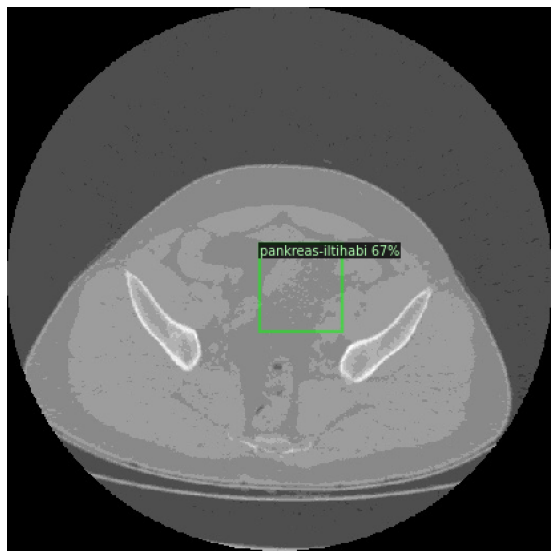

In [ ]:

from matplotlib.pyplot import figure
import cv2

namelist = {}

      
img = cv2.imread("/content/Faster-RCNN/test/"+ isimlist[1] + ".jpeg")
print(isimlist[1])
outputs = predictor(img)
v = Visualizer(img[:, :, ::-1],
               metadata=microcontroller_metadata, 
               scale=0.8, 
              # instance_mode=ColorMode.IMAGE_BW # removes the colors of unsegmented pixels
)
v = v.draw_instance_predictions(outputs["instances"].to("cpu"))
plt.figure(figsize = (10, 10))
plt.axis("off")
plt.imshow(cv2.cvtColor(v.get_image()[:, :, ::-1], cv2.COLOR_BGR2RGB))
   #file name ayırma
plt.show()

print(outputs)   

In [ ]:
with open("/content/Faster-RCNN/test/"+ isimlist[1] + ".json") as f:
     img_anns = json.load(f)
print(img_anns)

{'shapes': [{'label': 'bagirsak-divertikul-iltihabi', 'coords': [[244, 239], [309, 292]]}], 'image_path': '1188285_Seri4_30472300759.jpeg'}


In [ ]:
sum = 0
for i in range(0,len(iou_list),1):
  #print(iou_list[i])
  sum = sum + iou_list[i]
  avr = sum/len(coordinatlist)
sum2 = sum/len(iou_list)
print("iou ortalama",sum2)
print(len(iou_list))
testlist = glob("/content/Faster-RCNN/test/*.jpeg")
print(len(testlist))
print("koordinat listesi ortalama",avr)

iou ortalama 0.8092519063329981
1017
3179
koordinat listesi ortalama 0.21680958607498924


In [ ]:
jsonlist = glob("/content/Faster-RCNN/train/*.json")
for i in jsonlist:
  if(i == "/content/Faster-RCNN/train/25687_Seri4_38522861610.json"):
    with open(json_file) as f:
     img_anns = json.load(f)
     print(img_anns)

{'shapes': [{'label': 'safra-kesesi-iltihabi', 'coords': [[138, 164], [237, 292]]}], 'image_path': '21826_Seri2_37627270839.jpeg'}


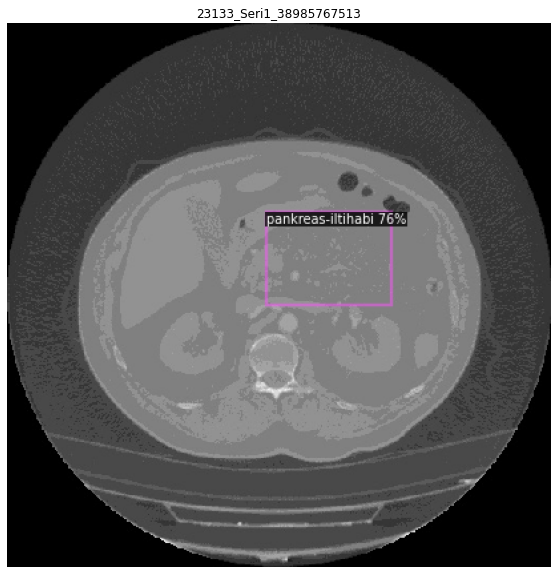

In [ ]:
from matplotlib.pyplot import figure
import cv2

namelist = {}

      
img = cv2.imread("/content/enhanced_train_test/test/"+ isimlist[0] + ".jpeg")
print(isimlist[0])
outputs = predictor(img)
v = Visualizer(img[:, :, ::-1],
               metadata=microcontroller_metadata, 
               scale=0.8, 
              # instance_mode=ColorMode.IMAGE_BW # removes the colors of unsegmented pixels
)
v = v.draw_instance_predictions(outputs["instances"].to("cpu"))
plt.figure(figsize = (10, 10))
plt.axis("off")
plt.imshow(cv2.cvtColor(v.get_image()[:, :, ::-1], cv2.COLOR_BGR2RGB))
   #file name ayırma
plt.show()

print(outputs)   


pankreas-iltihabi
0.7623762376237624


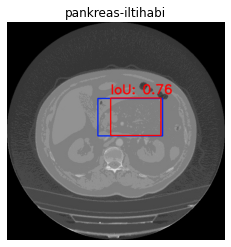

In [ ]:
import pandas as pd
import numpy as np
img = cv2.imread("/content/Faster-RCNN/train/" + isim +".jpeg")



dfpredict = pd.read_json("/content/predict annot/" +isim + ".json")


json_file = "/content/Faster-RCNN/train/" + isim + ".json"
with open(json_file) as f:
 
 img_anns = json.load(f)

annos = img_anns["shapes"] #shapes

a=1
for anno in annos:
 title = anno["label"]
 print(anno["label"]) 
 #print(anno["points"])
 dfanno = pd.DataFrame(anno['coords']) #mavi orjinal
 
 x1 = int(dfanno[0][0])
 y1 = int(dfanno[1][0])
 x2 = int(dfanno[0][1])
 y2 = int(dfanno[1][1])
 cv2.rectangle(img,(x1,y1),(x2,y2),(0,35,245), 2)
 
 for row in dfpredict.iterrows():
       #predict kırmızı 
       
  xp1 = int(row[1][0])
  yp1 = int(row[1][1])
  xp2 = int(row[1][2])
  yp2 = int(row[1][3])

  xA = max(x1, xp1)
  yA = max(y1, yp1)
  xB = min(x2, xp2)
  yB = min(y2, yp2)

  interArea = max(0, xB - xA + 1) * max(0, yB - yA + 1)
  boxAArea = (x2 - x1 + 1) * (y2 - y1 + 1)
  boxBArea = (xp2 - xp1 + 1) * (yp2 - yp1 + 1)

  iou = interArea / float(boxAArea + boxBArea - interArea)  
 
  cv2.rectangle(img,(xp1,yp1),(xp2,yp2),(255,0,0), 2) 
  cv2.putText(img, "IoU: {:.2f}".format(iou), (xp1,yp1-10), cv2.FONT_HERSHEY_SIMPLEX,1, (255,0,0),2, cv2.LINE_AA)
   
  if(iou>0.007):
   print(iou) 
plt.figure()
plt.axis("off")
plt.title(title,)
plt.imshow(img)


aort-anevrizma
0.8761061946902655


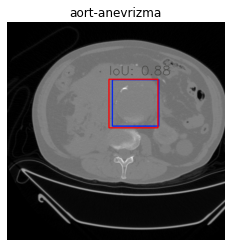

In [ ]:
import pandas as pd
import numpy as np
img = cv2.imread("/content/Faster-RCNN/test/25571_Seri2_26989174641.jpeg")
img = cv2.resize(img, (512,512))


dfpredict = pd.read_json("/content/predict annot/25571_Seri2_26989174641.jpe.json")


json_file = "/content/Faster-RCNN/test/25571_Seri2_26989174641.json"
with open(json_file) as f:
 
 img_anns = json.load(f)

annos = img_anns["shapes"] #shapes

a=1
for anno in annos:
 title = anno["label"]
 print(anno["label"]) 
 #print(anno["points"])
 dfanno = pd.DataFrame(anno['coords']) #mavi orjinal
 
 x1 = int(dfanno[0][0])
 y1 = int(dfanno[1][0])
 x2 = int(dfanno[0][1])
 y2 = int(dfanno[1][1])
 cv2.rectangle(img,(x1,y1),(x2,y2),(0,35,245), 2)
 
 for row in dfpredict.iterrows():
       #predict kırmızı 
       
  xp1 = int(row[1][0])
  yp1 = int(row[1][1])
  xp2 = int(row[1][2])
  yp2 = int(row[1][3])

  xA = max(x1, xp1)
  yA = max(y1, yp1)
  xB = min(x2, xp2)
  yB = min(y2, yp2)

  interArea = max(0, xB - xA + 1) * max(0, yB - yA + 1)
  boxAArea = (x2 - x1 + 1) * (y2 - y1 + 1)
  boxBArea = (xp2 - xp1 + 1) * (yp2 - yp1 + 1)

  iou = interArea / float(boxAArea + boxBArea - interArea)  
 
  cv2.rectangle(img,(xp1,yp1),(xp2,yp2),(255,0,0), 2) 
  cv2.putText(img, "IoU: {:.2f}".format(iou), (xp1,yp1-10), cv2.FONT_HERSHEY_SIMPLEX,1, (55,55,52),1, cv2.LINE_AA)
   
  if(iou>0.007):
   print(iou) 
plt.figure()
plt.axis("off")
plt.title(title,)
plt.imshow(img)


In [ ]:
import pandas as pd
import numpy as np
from glob import glob
import json

json_list = glob("/content/faster RCNN/test/*.json")
jpeg_list = glob("/content/faster RCNN/test/*.jpeg")

for i in jpeg_list:
   img = cv2.imread(i)
   img = cv2.resize(img,(256,256))
   id_jpeg = i.split("/")[4].split(".jpg")[0]
   title2 = id_jpeg
   for a in json_list:
     temp_id_json = a.split("/")[4].split(".json")[0]
     
     if id_jpeg == temp_id_json:
       id_json = temp_id_json
   
   
   json_file = "/content/faster RCNN/test/" + id_json +".json"
   
   with open(json_file) as f:
     img_anns = json.load(f)
     
   try:
    dfpredict = pd.read_json("/content/predict annot/" + id_json + ".json")
   except ValueError as e:
     print(e)   


   annos = img_anns["shapes"] #shapes
   
   
   for anno in annos:
     title = anno["label"]
     #print(anno["label"]) 
     #print(anno["points"])
     dfanno = pd.DataFrame(anno['points']) #mavi orjinal
     
     x1 = int(dfanno[0][0])
     y1 = int(dfanno[1][0])
     x2 = int(dfanno[0][1])
     y2 = int(dfanno[1][1])
     cv2.rectangle(img,(x1,y1),(x2,y2),(0,35,245), 2)
     
     try:
       for row in dfpredict.iterrows():
             #predict kırmızı 
             
         xp1 = int(row[1][0])
         yp1 = int(row[1][1])
         xp2 = int(row[1][2])
         yp2 = int(row[1][3])
     
         xA = max(x1, xp1)
         yA = max(y1, yp1)
         xB = min(x2, xp2)
         yB = min(y2, yp2)
     
         interArea = max(0, xB - xA + 1) * max(0, yB - yA + 1)
         boxAArea = (x2 - x1 + 1) * (y2 - y1 + 1)
         boxBArea = (xp2 - xp1 + 1) * (yp2 - yp1 + 1)
     
         iou = interArea / float(boxAArea + boxBArea - interArea)  
       
         cv2.rectangle(img,(xp1,yp1),(xp2,yp2),(255,0,0), 2) 
         cv2.putText(img, "IoU: {:.2f}".format(iou), (xp1,yp1-10), cv2.FONT_HERSHEY_SIMPLEX,0.5, (55,55,52),1, cv2.LINE_AA)
     except NameError as e:
        print(e)  
       
         
   plt.figure()
   plt.title(title+title2)
   plt.axis("off")
   plt.imshow(img)
   

In [ ]:
TP=0
FN=0
FP=0
from tqdm import tqdm
import math
for d in tqdm(test_dataset_dicts):

    bboxs = []
    bbox_center_x = []
    bbox_center_y = []


    predicted_centers_x = []
    predicted_centers_y = []

    path = d["file_name"].replace('\\','/')
    im = cv2.imread(path)

    outputs = predictor(im) #going over image by image to find predictions

    i = d['annotations']
    for i in range(len(d['annotations'])):
        bboxs.append(d['annotations'][i]['bbox']) #bboxs have the 

    bboxs = np.array(bboxs)
    predicted_bboxs = outputs["instances"].pred_boxes.to("cpu").tensor.numpy()

    for bbox in bboxs:
        bbox_center_x.append((bbox[0]+bbox[0]+bbox[2])/2)
        bbox_center_y.append((bbox[1]+bbox[1]+bbox[3])/2)

    for predicted_bbox in predicted_bboxs:
        predicted_centers_x.append((predicted_bbox[0]+predicted_bbox[2])/2)
        predicted_centers_y.append((predicted_bbox[1]+predicted_bbox[3])/2)



    num_tumor = len(bbox_center_x)
    pred_num_tumor = len(predicted_centers_x)
    if num_tumor > pred_num_tumor:
        FN += num_tumor - pred_num_tumor

    temp_bbox_x = bbox_center_x
    temp_bbox_y = bbox_center_y

    for i in range(len(predicted_centers_x)):
        for j in range(len(temp_bbox_x)):
            if (math.sqrt( (temp_bbox_x[j] - predicted_centers_x[i])**2 + 
                (temp_bbox_y[j] - predicted_centers_y[i])**2 ) ) <= 30:
                TP += 1

                break
            if j == ( len(temp_bbox_x)-1 ):
                FP += 1




Precision = (TP/(TP+FP))
Recall = (TP/(TP+FN))

f_score = float(2*(Recall * Precision) / (Recall + Precision))
print("\n",f_score)

100%|██████████| 14/14 [00:01<00:00,  7.03it/s]


In [ ]:
os.mkdir("predict annot1")

In [ ]:
from matplotlib.pyplot import figure
namelist = {}

      
img = cv2.imread("/content/Faster-RCNN/test/25623_Seri7_35428631398.jpeg")

outputs = predictor(img)
v = Visualizer(img[:, :, ::-1],
               metadata=microcontroller_metadata, 
               scale=0.8, 
              # instance_mode=ColorMode.IMAGE_BW # removes the colors of unsegmented pixels
)
v = v.draw_instance_predictions(outputs["instances"].to("cpu"))
plt.figure(figsize = (10, 10))
plt.axis("off")
plt.imshow(cv2.cvtColor(v.get_image()[:, :, ::-1], cv2.COLOR_BGR2RGB))
    #file name ayırma
plt.show()

b = str(outputs["instances"]) 
predictannot = b.split("tensor(")[1].strip(" device='cuda:0'), scores:")
#  print(b,"\n")# dosya formatını görmek isterseniz açın
#  print(predictannot)
filename = str(d["file_name"].split("/")[4].strip(".jpeg"))
#  print(filename)



In [ ]:
"""def bb_intersection_over_union(boxA, boxB):
	# determine the (x, y)-coordinates of the intersection rectangle
	xA = max(boxA[0], boxB[0])
	yA = max(boxA[1], boxB[1])
	xB = min(boxA[2], boxB[2])
	yB = min(boxA[3], boxB[3])
	# compute the area of intersection rectangle
	interArea = max(0, xB - xA + 1) * max(0, yB - yA + 1)
	# compute the area of both the prediction and ground-truth
	# rectangles
	boxAArea = (boxA[2] - boxA[0] + 1) * (boxA[3] - boxA[1] + 1)
	boxBArea = (boxB[2] - boxB[0] + 1) * (boxB[3] - boxB[1] + 1)
	# compute the intersection over union by taking the intersection
	# area and dividing it by the sum of prediction + ground-truth
	# areas - the interesection area
	iou = interArea / float(boxAArea + boxBArea - interArea)
	# return the intersection over union value
	return iou"""

           0          1
0  56.262295   9.836066
1  92.874317  56.830601 

            0           1
0  140.961749   94.535519
1  177.300546  145.628415 

            0          1
0  188.502732  47.540984
1  226.207650  93.715847 



Text(0.5, 1.0, 'mavi orjinal kırmızı predict')

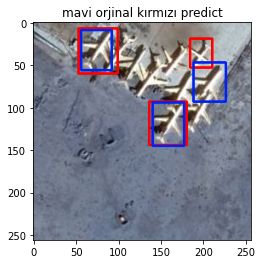

In [ ]:
import pandas as pd
import numpy as np
img = cv2.imread("/content/faster RCNN/test/airplane_239.jpg")
img = cv2.resize(img, (256,256))
df = pd.read_json("/content/predict annot/airplane_239.json")


for row in df.iterrows():
#  print(row,"\n\n\n")
  x1 = int(row[1][0])
  y1 = int(row[1][1])
  x2 = int(row[1][2])
  y2 = int(row[1][3])
  cv2.rectangle(img,(x1,y1),(x2,y2),(255,0,0), 2)

json_file = "/content/faster RCNN/test/airplane_239.json"
with open(json_file) as f:
    img_anns = json.load(f)

annos = img_anns["shapes"] #shapes
#print(annos,"\n")
listanno = []
for anno in annos:

  #print(anno["points"])
  dfanno = pd.DataFrame(anno['points'])
  print(dfanno,"\n")
  x1 = int(dfanno[0][0])
  y1 = int(dfanno[1][0])
  x2 = int(dfanno[0][1])
  y2 = int(dfanno[1][1])
  cv2.rectangle(img,(x1,y1),(x2,y2),(0,35,245), 2)
#  for row in dfanno.iterrows():
#    print(row)
#     x1 = int(row[0][0])
#     y1 = int(row[0][1])
#     x2 = int(row[1][0])
#     y2 = int(row[1][1])
#     cv2.rectangle(img,(x1,y1),(x2,y2),(0,255,0), 2)





#  for i in anno['points']:
#    
#    #print(i)
#    px = i[0]
#    py = i[1]
#    listanno.append(px)
#    listanno.append(py)
     # print(i[1])
   # px = [a[0] for a in anno['points']] # x coord
    #listanno.append(px)
   # py = [a[1] for a in anno['points']] # y-coord 
    #listanno.append(py)
#print(len(listanno))
#print(px):
#for x in range(len(listanno)):
#  px1 = listanno[0]
df = pd.DataFrame(listanno)
plt.figure()
plt.imshow(img)
plt.title("mavi orjinal kırmızı predict")
#print(df)


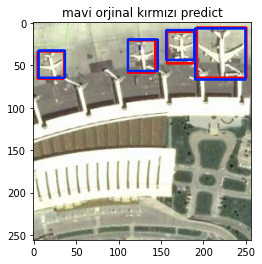

In [ ]:
import pandas as pd
import numpy as np
img = cv2.imread("/content/faster RCNN/test/airplane_253.jpg")
img = cv2.resize(img, (256,256))
df = pd.read_json("/content/predict annot/airplane_253.json")


for row in df.iterrows():

  x1 = int(row[1][0])
  y1 = int(row[1][1])
  x2 = int(row[1][2])
  y2 = int(row[1][3])
  cv2.rectangle(img,(x1,y1),(x2,y2),(255,0,0), 2)

json_file = "/content/faster RCNN/test/airplane_253.json"
with open(json_file) as f:
    img_anns = json.load(f)
annos = img_anns["shapes"] #shapes
#print(annos,"\n")
listanno = []
for anno in annos:

  #print(anno["points"])
  dfanno = pd.DataFrame(anno['points'])
  
  x1 = int(dfanno[0][0])
  y1 = int(dfanno[1][0])
  x2 = int(dfanno[0][1])
  y2 = int(dfanno[1][1])
  cv2.rectangle(img,(x1,y1),(x2,y2),(0,35,245), 2)



df = pd.DataFrame(listanno)
plt.figure()

plt.title("mavi orjinal kırmızı predict")
plt.imshow(img)
